# ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN
**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('data/Orange_Telecom_Churn_Data.csv')
print('Размерность:', data.shape)
print('Пропущенных значений:', data.isnull().sum().sum())
data.head()

Размерность: (5000, 21)
Пропущенных значений: 0


,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
> В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность и вызовет высокий риск переобучения для алгоритма KNN.

In [2]:
# area_code записан числом, но по смыслу это категория
cat_cols = ['state', 'area_code', 'phone_number', 'intl_plan', 'voice_mail_plan', 'churned']
print(data[cat_cols].nunique())

data = data.drop(columns=['state', 'area_code', 'phone_number'])
print('Осталось колонок:', data.shape[1])

state                51
area_code             3
phone_number       5000
intl_plan             2
voice_mail_plan       2
churned               2
dtype: int64
Осталось колонок: 18


**Ответ.** У `phone_number` 5000 уникальных значений на 5000 строк, то есть это просто идентификатор клиента. У `state` 51 значение, у `area_code` всего 3. Оставшиеся категориальные колонки (`intl_plan`, `voice_mail_plan`) бинарные, их можно спокойно закодировать в 0/1.

Если применить `OneHotEncoder` к `phone_number`, получится 5000 новых колонок, и в каждой строке будет ровно одна единица. Матрица станет 5000 × 5016, почти вся из нулей, то есть данных в памяти становится примерно в 300 раз больше. Но главная проблема в расстояниях. Для двух любых разных клиентов one-hot часть всегда добавляет к квадрату евклидова расстояния одно и то же число: $(1-0)^2 + (0-1)^2 = 2$. После `MinMaxScaler` каждый числовой признак даёт вклад не больше 1, а обычно намного меньше, поэтому эта двойка почти полностью забивает полезную разницу между клиентами, и соседи выбираются почти случайно.

С переобучением похожая история. Признак уникален для каждой строки, поэтому модель может запомнить клиента по номеру, а для нового клиента с новым номером эти 5000 колонок будут нулевыми и ничего не дадут. С `state` слабее, но то же самое: 51 колонка, в каждом штате около 100 клиентов, и соседи будут искаться в основном внутри своего штата. Выборка фактически дробится на маленькие группы, и модель подстраивается под них.

### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
> С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в распределении данных присутствуют выбросы (outliers)?

In [3]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

cols =['account_length', 'total_day_charge']
sample = data[cols].iloc[:3]
print(sample)

def euclid(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

scaled = MinMaxScaler().fit(data[cols]).transform(sample)
raw = sample.values

for i, j in [(0, 1), (0, 2), (1, 2)]:
    print(f'клиенты {i} и {j}: без масштабирования {euclid(raw[i], raw[j]):6.2f}, '
          f'после MinMaxScaler {euclid(scaled[i], scaled[j]):.3f}')

   account_length  total_day_charge
0             128             45.07
1             107             27.47
2             137             41.38
клиенты 0 и 1: без масштабирования  27.40, после MinMaxScaler 0.307
клиенты 0 и 2: без масштабирования   9.73, после MinMaxScaler 0.072
клиенты 1 и 2: без масштабирования  33.07, после MinMaxScaler 0.264


In [4]:
# вклад каждого признака в квадрат расстояния между клиентами 0 и 2
diff_raw = (raw[0] - raw[2]) ** 2
diff_scaled = (scaled[0] - scaled[2]) ** 2
print('без масштабирования:', (diff_raw / diff_raw.sum()).round(3))
print('после MinMaxScaler: ', (diff_scaled / diff_scaled.sum()).round(3))

без масштабирования: [0.856 0.144]
после MinMaxScaler:  [0.266 0.734]


In [5]:
# добавляем одного клиента с аномально большим total_day_charge
charge = np.append(data['total_day_charge'].values, 500).reshape(-1, 1)

mm = MinMaxScaler().fit_transform(charge)[:-1]
st = StandardScaler().fit_transform(charge)[:-1]
print(f'MinMaxScaler:   обычные клиенты в диапазоне [{mm.min():.3f}, {mm.max():.3f}]')
print(f'StandardScaler: обычные клиенты в диапазоне [{st.min():.3f}, {st.max():.3f}]')

MinMaxScaler:   обычные клиенты в диапазоне [0.000, 0.120]
StandardScaler: обычные клиенты в диапазоне [-2.718, 2.565]


**Ответ.** Без масштабирования `account_length` меняется в пределах сотен, а `total_day_charge` в пределах десятков, поэтому расстояние почти целиком определяется длительностью договора. После `MinMaxScaler` оба признака лежат в [0, 1] и вклад распределяется честнее, видно, что у пары клиентов 0 и 2 доли сильно меняются.

С выбросом `MinMaxScaler` ведёт себя плохо: минимум и максимум берутся по одной аномальной точке, и все обычные клиенты сжимаются в узкий кусок около 0. Признак почти перестаёт влиять на расстояние. `StandardScaler` тоже зависит от выброса (среднее и стандартное отклонение сдвигаются), но меньше, обычные значения остаются нормально разнесены. Думаю, при сильных выбросах лучше вообще `RobustScaler`, он считает по медиане и квартилям.

### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
> В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него на синтетическом наборе из 100 000 объектов.

In [6]:
!pip install -q scikit-learn-intelex

import sys
# в Colab пакет ставится в site-packages, а этой папки нет в sys.path
sys.path.append(f'/usr/local/lib/python{sys.version_info.major}.{sys.version_info.minor}/site-packages')

In [8]:
import time
import timeit
from sklearn.neighbors import KNeighborsClassifier

# Создание синтетических данных
rng = np.random.default_rng(42)
X_syn = rng.random((100000, 10))
y_syn = rng.integers(0, 2, 100000)
X_query = rng.random((2000, 10))

def measure(model_class):
    knn = model_class(n_neighbors=5)
    fit_time = timeit.timeit(lambda: knn.fit(X_syn, y_syn), number=3) / 3
    start = time.perf_counter()
    knn.predict(X_query)
    predict_time = time.perf_counter() - start
    return fit_time, predict_time

fit_plain, pred_plain = measure(KNeighborsClassifier)

from sklearnex import patch_sklearn, unpatch_sklearn
patch_sklearn()
# после патча класс нужно импортировать заново, иначе останется старая версия
from sklearn.neighbors import KNeighborsClassifier
fit_intel, pred_intel = measure(KNeighborsClassifier)

unpatch_sklearn()
from sklearn.neighbors import KNeighborsClassifier

print(f'fit:     без патча {fit_plain:.3f} с, с патчем {fit_intel:.3f} с '
      f'(в {fit_plain / fit_intel:.1f} раза быстрее)')
print(f'predict: без патча {pred_plain:.3f} с, с патчем {pred_intel:.3f} с '
      f'(в {pred_plain / pred_intel:.1f} раза быстрее)')

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


fit:     без патча 0.641 с, с патчем 0.191 с (в 3.4 раза быстрее)
predict: без патча 2.085 с, с патчем 0.362 с (в 5.8 раза быстрее)


**Ответ.** `patch_sklearn()` подменяет классы sklearn на версии из библиотеки Intel oneDAL, при этом интерфейс остаётся тем же. Для KNN это значит, что KD-Tree строится и обходится в скомпилированном коде, а при полном переборе расстояния считаются пачками через матричное умножение с векторными инструкциями процессора (AVX2/AVX-512), то есть за одну инструкцию обрабатывается сразу несколько чисел. Плюс вычисления распараллелены по всем ядрам.

По замеру `fit` с патчем стал быстрее примерно в 3 раза, а `predict` почти в 6 раз. Думаю, разница в том, что `fit` у KNN и так быстрый, обучение по сути сводится к сохранению данных и построению дерева. Основное время уходит на `predict`, где для каждой точки ищутся соседи среди 100 000 объектов, поэтому там ускорение и заметнее всего. Точные цифры при каждом запуске немного отличаются. Патч после замера я отключил, чтобы остальные упражнения считались обычным sklearn.

### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
> Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

In [9]:
from scipy.spatial import distance
from sklearn.datasets import make_moons

def minkowski_distance(x, y, p):
    if p == np.inf:
        return np.max(np.abs(x - y))
    return np.sum(np.abs(x - y) ** p) ** (1 / p)

a = np.array([1.0, 5.0])
b = np.array([4.0, 1.0])
for p in [1, 2, 3, 10, 100, np.inf]:
    print(f'p = {p}: {minkowski_distance(a, b, p):.4f}')

# проверка со scipy
print(distance.cityblock(a, b), distance.euclidean(a, b), distance.chebyshev(a, b))

p = 1: 7.0000
p = 2: 5.0000
p = 3: 4.4979
p = 10: 4.0220
p = 100: 4.0000
p = inf: 4.0000
7.0 5.0 4.0


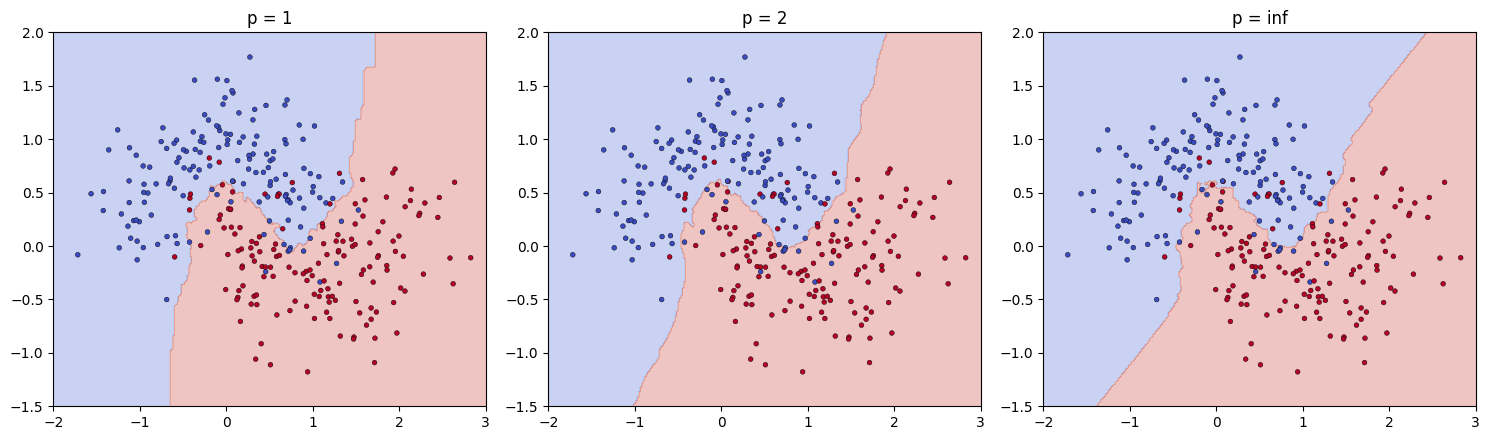

In [10]:
X_2d, y_2d = make_moons(n_samples=300, noise=0.3, random_state=42)

xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, p in zip(axes, [1, 2, np.inf]):
    knn = KNeighborsClassifier(n_neighbors=15, p=p)
    knn.fit(X_2d, y_2d)
    zz = knn.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, cmap='coolwarm', s=12, edgecolor='k', linewidth=0.3)
    ax.set_title(f'p = {p}')
plt.tight_layout()
plt.show()

**Ответ.** Для точек (1, 5) и (4, 1) расстояние падает от 7 при p = 1 до 5 при p = 2 и стремится к 4 при больших p. При $p \to \infty$ в сумме остаётся только самая большая разница по одной координате, это и есть расстояние Чебышёва. Значения совпали со scipy.

Между облаками точек границы почти одинаковые, а вот вдали от данных отличаются сильно. При p = 1 граница уходит вертикальными и горизонтальными линиями, при p = ∞ идёт по диагонали под 45°, а при p = 2 получается что-то среднее. Думаю, это из-за того, как выглядит «круг» вокруг точки: при p = 1 это ромб, при p = 2 обычный круг, при p = ∞ квадрат. Там, где соседи далеко, именно форма этого «круга» решает, какой класс окажется ближе.

### Упражнение 5: Парадокс 100% точности при K=3 на обучающей выборке
> Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

In [11]:
from sklearn.model_selection import train_test_split

# подготовка как в ноутбуке: бинарные колонки в 0/1, признаки в [0, 1]
data['intl_plan'] = (data['intl_plan'] == 'yes').astype(int)
data['voice_mail_plan'] = (data['voice_mail_plan'] == 'yes').astype(int)
data['churned'] = data['churned'].astype(int)

X = data.drop(columns='churned')
y = data['churned']
X_scaled = MinMaxScaler().fit_transform(X)

for params in [dict(n_neighbors=1), dict(n_neighbors=3), dict(n_neighbors=3, weights='distance')]:
    knn = KNeighborsClassifier(**params).fit(X_scaled, y)
    print(params, 'accuracy на тех же данных:', knn.score(X_scaled, y))

{'n_neighbors': 1} accuracy на тех же данных: 1.0
{'n_neighbors': 3} accuracy на тех же данных: 0.9422
{'n_neighbors': 3, 'weights': 'distance'} accuracy на тех же данных: 1.0


In [12]:
knn = KNeighborsClassifier(n_neighbors=1).fit(X_scaled, y)
dist, idx = knn.kneighbors(X_scaled[:5])
print('ближайший сосед:', idx.ravel())
print('расстояние:     ', dist.ravel().round(6))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = MinMaxScaler().fit(X_tr)
knn = KNeighborsClassifier(n_neighbors=1).fit(scaler.transform(X_tr), y_tr)
print('K=1, accuracy на отложенной выборке:', round(knn.score(scaler.transform(X_te), y_te), 4))

ближайший сосед: [0 1 2 3 4]
расстояние:      [0. 0. 0. 0. 0.]
K=1, accuracy на отложенной выборке: 0.878


**Ответ.** KNN ничего не обучает, модель это и есть сохранённые данные. Если предсказывать на тех же точках, то ближайшим соседом точки $x_i$ всегда будет она сама, с расстоянием 0, это видно по выводу выше (индексы 0, 1, 2, 3, 4 и нулевые расстояния). При K = 1 модель просто возвращает собственную метку точки, поэтому точность 1.0.

С `weights='distance'` то же самое при любом K: вес соседа равен $1/d$, и при $d = 0$ вес самой точки бесконечный, остальные соседи на результат уже не влияют. При K = 3 с обычными весами точность уже не 1.0, потому что два других соседа могут перевесить.

Это крайний случай переобучения: модель запомнила выборку, а не выучила закономерность. На отложенной выборке K = 1 даёт 0.878, а это совсем немного больше, чем если всегда отвечать «не ушёл» (0.859). Поэтому оценивать KNN нужно только на данных, которых модель не видела.

### Упражнение 6: Реализация собственного алгоритма KNN с нуля
> Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [13]:
class CustomKNN:
    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X_test, k=3):
        X_test = np.asarray(X_test, dtype=float)
        # квадрат расстояния через (a - b)^2 = a^2 + b^2 - 2ab, без циклов по точкам
        d2 = (np.sum(X_test ** 2, axis=1)[:, None]
              + np.sum(self.X_train ** 2, axis=1)[None, :]
              - 2 * X_test @ self.X_train.T)
        nearest = np.argsort(d2, axis=1)[:, :k]
        labels = self.y_train[nearest]
        return np.array([np.bincount(row).argmax() for row in labels])

In [14]:
X_small = X_scaled[:1000]
y_small = y.values[:1000]
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_small, y_small, test_size=0.3,
                                              random_state=42, stratify=y_small)

custom = CustomKNN().fit(Xs_tr, ys_tr)
pred_custom = custom.predict(Xs_te, k=5)

sk = KNeighborsClassifier(n_neighbors=5).fit(Xs_tr, ys_tr)
pred_sk = sk.predict(Xs_te)

print('accuracy CustomKNN:', round(np.mean(pred_custom == ys_te), 4))
print('accuracy sklearn:  ', round(np.mean(pred_sk == ys_te), 4))
print('совпадение предсказаний:', np.mean(pred_custom == pred_sk))

accuracy CustomKNN: 0.9033
accuracy sklearn:   0.9033
совпадение предсказаний: 1.0


**Ответ.** Предсказания моего класса полностью совпали с `KNeighborsClassifier`, значит, расстояния и голосование посчитаны правильно. Расстояния считаются сразу для всей матрицы через матричное умножение, поэтому циклов по точкам нет, остался только короткий цикл для голосования. Минус в том, что матрица расстояний занимает память размером test × train, на всех 5000 клиентах это уже заметно.

### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
> Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

In [15]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

# масштабирование внутри пайплайна, чтобы скейлер не видел валидационный фолд
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for k in range(1, 31):
    model = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(model, X_tr, y_tr, cv=skf, scoring='accuracy')
    cv_results.append((k, scores.mean(), scores.std()))

cv_df = pd.DataFrame(cv_results, columns=['k', 'mean_acc', 'std_acc'])
cv_df['error'] = 1 - cv_df['mean_acc']

best_k = int(cv_df.loc[cv_df['error'].idxmin(), 'k'])
print(cv_df.round(4).to_string(index=False))
print('Оптимальное K:', best_k)

 k  mean_acc  std_acc  error
 1    0.8778   0.0057 0.1222
 2    0.8918   0.0054 0.1082
 3    0.9062   0.0041 0.0938
 4    0.8968   0.0073 0.1033
 5    0.9050   0.0074 0.0950
 6    0.8948   0.0056 0.1053
 7    0.9038   0.0060 0.0963
 8    0.8920   0.0032 0.1080
 9    0.9000   0.0042 0.1000
10    0.8918   0.0036 0.1082
11    0.9005   0.0042 0.0995
12    0.8880   0.0041 0.1120
13    0.8962   0.0035 0.1038
14    0.8882   0.0041 0.1118
15    0.8938   0.0025 0.1062
16    0.8885   0.0033 0.1115
17    0.8908   0.0023 0.1092
18    0.8875   0.0026 0.1125
19    0.8915   0.0036 0.1085
20    0.8853   0.0046 0.1147
21    0.8882   0.0050 0.1118
22    0.8848   0.0040 0.1152
23    0.8880   0.0042 0.1120
24    0.8842   0.0052 0.1158
25    0.8868   0.0036 0.1133
26    0.8835   0.0024 0.1165
27    0.8865   0.0042 0.1135
28    0.8840   0.0022 0.1160
29    0.8858   0.0042 0.1142
30    0.8832   0.0029 0.1168
Оптимальное K: 3


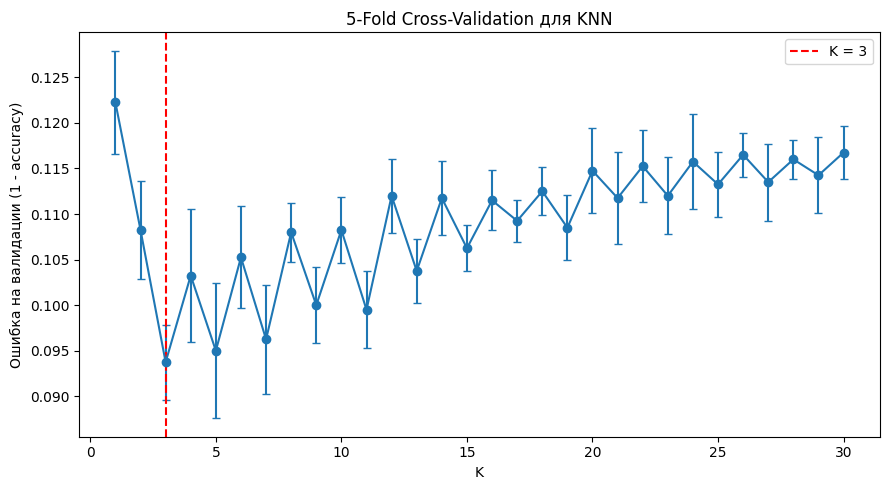

In [16]:
plt.figure(figsize=(9, 5))
plt.errorbar(cv_df['k'], cv_df['error'], yerr=cv_df['std_acc'], marker='o', capsize=3)
plt.axvline(best_k, color='red', linestyle='--', label=f'K = {best_k}')
plt.xlabel('K')
plt.ylabel('Ошибка на валидации (1 - accuracy)')
plt.title('5-Fold Cross-Validation для KNN')
plt.legend()
plt.tight_layout()
plt.show()

**Ответ.** Минимальная ошибка получилась при K = 3 (accuracy 0.906), но K = 5 почти такое же (0.905), разница меньше стандартного отклонения. После K ≈ 11 ошибка постепенно растёт: соседей становится слишком много, и модель всё чаще просто отвечает «не ушёл», как большинство.

Интересно, что график идёт зигзагом: при чётных K ошибка всегда выше, чем при соседних нечётных. Думаю, это из-за ничьих. При чётном K голоса могут разделиться поровну, и тогда sklearn выбирает класс с меньшим номером, то есть 0 («не ушёл»). Для редкого класса это минус, поэтому для бинарной задачи лучше брать нечётное K.

### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
> В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие — меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

In [17]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.dummy import DummyClassifier

knn_best = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=best_k))
knn_best.fit(X_tr, y_tr)
y_pred = knn_best.predict(X_te)

dummy = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
print('Accuracy модели, которая всегда говорит «не ушёл»:', round(dummy.score(X_te, y_te), 4))
print(f'Accuracy KNN (K = {best_k}):', round(accuracy_score(y_te, y_pred), 4))
print()
print(confusion_matrix(y_te, y_pred))
print(classification_report(y_te, y_pred, target_names=['остался', 'ушёл']))

Accuracy модели, которая всегда говорит «не ушёл»: 0.859
Accuracy KNN (K = 3): 0.894

[[834  25]
 [ 81  60]]
              precision    recall  f1-score   support

     остался       0.91      0.97      0.94       859
        ушёл       0.71      0.43      0.53       141

    accuracy                           0.89      1000
   macro avg       0.81      0.70      0.74      1000
weighted avg       0.88      0.89      0.88      1000



**Ответ.** Ушедших клиентов всего около 14%, поэтому модель, которая вообще ничего не учит и всегда отвечает «не ушёл», уже получает accuracy 0.859. На этом фоне 0.894 у KNN выглядит не так впечатляюще, и сама accuracy почти ничего не говорит о том, находим ли мы тех, кто уходит, а для бизнеса важны именно они.

По матрице ошибок видно, что из 141 ушедшего клиента модель нашла только 60, а 81 пропустила. Recall для класса «ушёл» всего 0.43, хотя precision 0.71 нормальный: если модель сказала «уйдёт», то обычно права, но большую часть уходящих она не замечает. Поэтому для этой задачи я бы смотрел на recall и F1 по классу «ушёл» (F1 = 0.53), а не на accuracy.

### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
> Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

In [18]:
from sklearn.metrics import f1_score

# в части обучающей выборки меняем метку на противоположную, это и есть шум
noise_levels = [0, 0.05, 0.1, 0.2, 0.3]
X_tr_s = scaler.transform(X_tr)
X_te_s = scaler.transform(X_te)

rows = []
for noise in noise_levels:
    for weights in ['uniform', 'distance']:
        accs, f1s = [], []
        for seed in range(5):
            rng = np.random.default_rng(seed)
            y_noisy = y_tr.values.copy()
            flip = rng.choice(len(y_noisy), int(noise * len(y_noisy)), replace=False)
            y_noisy[flip] = 1 - y_noisy[flip]

            knn = KNeighborsClassifier(n_neighbors=best_k, weights=weights).fit(X_tr_s, y_noisy)
            pred = knn.predict(X_te_s)
            accs.append(accuracy_score(y_te, pred))
            f1s.append(f1_score(y_te, pred))
        rows.append((noise, weights, np.mean(accs), np.mean(f1s)))

noise_df = pd.DataFrame(rows, columns=['шум', 'weights', 'accuracy', 'f1 (ушёл)'])
print(noise_df.pivot(index='шум', columns='weights', values=['accuracy', 'f1 (ушёл)']).round(4))

        accuracy         f1 (ушёл)        
weights distance uniform  distance uniform
шум                                       
0.00      0.8940  0.8940    0.5310  0.5310
0.05      0.8840  0.8836    0.5125  0.5116
0.10      0.8642  0.8640    0.4928  0.4924
0.20      0.7946  0.7950    0.3654  0.3660
0.30      0.7016  0.7018    0.3035  0.3037


In [19]:
# второй вариант: выбросы с неправильной меткой лежат совсем рядом с проверяемыми клиентами
rows = []
for n_out in [0, 100, 200, 400]:
    for weights in ['uniform', 'distance']:
        accs = []
        for seed in range(5):
            rng = np.random.default_rng(seed)
            idx = rng.choice(len(X_te_s), n_out, replace=False)
            X_out = X_te_s[idx] + rng.normal(0, 0.05, (n_out, X_te_s.shape[1]))
            y_out = 1 - y_te.values[idx]

            knn = KNeighborsClassifier(n_neighbors=best_k, weights=weights)
            knn.fit(np.vstack([X_tr_s, X_out]), np.r_[y_tr.values, y_out])
            accs.append(accuracy_score(y_te, knn.predict(X_te_s)))
        rows.append((n_out, weights, np.mean(accs)))

out_df = pd.DataFrame(rows, columns=['выбросов', 'weights', 'accuracy'])
print(out_df.pivot(index='выбросов', columns='weights', values='accuracy').round(4))

weights   distance  uniform
выбросов                   
0           0.8940   0.8940
100         0.8734   0.8820
200         0.8532   0.8672
400         0.7952   0.8280


**Ответ.** В первом эксперименте, где метки перевёрнуты у случайных клиентов, разницы между `uniform` и `distance` почти нет, точность падает одинаково. Думаю, это потому, что случайная ошибочная точка обычно находится не ближе к новому клиенту, чем правильные, и вес у неё такой же, как у остальных.

Во втором эксперименте я положил выбросы с неправильной меткой совсем рядом с проверяемыми клиентами, и тут `distance` проигрывает заметно (при 400 выбросах 0.795 против 0.828). Вес соседа равен $1/d$, поэтому одна очень близкая неправильная точка получает огромный вес и перевешивает двух других соседей, даже если они правильные. При `uniform` у неё всего один голос из K. Получается, что `weights='distance'` более уязвим к шуму, но только когда выброс оказывается ближайшим соседом. Думаю, при большем K эта разница будет меньше, потому что один близкий выброс тогда перевешивает не 2, а больше соседей.

### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
> Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

In [20]:
rows = []
for n_noise in [0, 5, 10, 20, 50, 100]:
    rng = np.random.default_rng(42)
    X_noise = np.hstack([X.values, rng.random((len(X), n_noise))])
    model = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=best_k))
    acc = cross_val_score(model, X_noise, y, cv=skf, scoring='accuracy').mean()
    f1 = cross_val_score(model, X_noise, y, cv=skf, scoring='f1').mean()
    rows.append((X.shape[1] + n_noise, n_noise, acc, f1))

dim_df = pd.DataFrame(rows, columns=['всего признаков', 'шумовых', 'accuracy', 'f1 (ушёл)'])
print(dim_df.round(4).to_string(index=False))

 всего признаков  шумовых  accuracy  f1 (ушёл)
              17        0    0.8992     0.5435
              22        5    0.8706     0.3528
              27       10    0.8624     0.2906
              37       20    0.8468     0.2187
              67       50    0.8394     0.1290
             117      100    0.8430     0.1344


In [21]:
# почему так: отношение расстояния до самого дальнего и самого ближнего соседа
for n_noise in [0, 20, 100]:
    rng = np.random.default_rng(42)
    X_noise = MinMaxScaler().fit_transform(np.hstack([X.values, rng.random((len(X), n_noise))]))
    d = np.sqrt(np.sum((X_noise[1:] - X_noise[0]) ** 2, axis=1))
    print(f'{X.shape[1] + n_noise} признаков: max/min расстояние = {d.max() / d.min():.2f}')

17 признаков: max/min расстояние = 7.98
37 признаков: max/min расстояние = 2.50
117 признаков: max/min расстояние = 1.55


**Ответ.** Уже 5 случайных колонок сильно портят модель: F1 по ушедшим падает с 0.54 до 0.35, а при 50–100 шумовых колонках до 0.13. Accuracy при этом снижается до 0.84, то есть даже ниже, чем у модели, которая всегда отвечает «не ушёл» (0.859). Это ещё раз показывает, почему в упражнении 8 accuracy вводила в заблуждение: по ней падение выглядит небольшим, а по F1 модель почти перестала находить уходящих.

Причина видна во второй ячейке. На исходных данных самый дальний клиент дальше самого ближнего почти в 8 раз, а при 117 признаках только в 1.55 раза. Каждая шумовая колонка добавляет к расстоянию случайную величину, и эти добавки складываются, поэтому все клиенты становятся примерно одинаково далеко друг от друга. Понятие «ближайший сосед» теряет смысл, и KNN выбирает соседей почти случайно. Поэтому для KNN важно убирать лишние признаки, это я попробую в упражнении 12 через `SelectKBest`.

### Упражнение 11: KNN для регрессии против классификации
> Хотя в ноутбуке мы использовали `KNeighborsClassifier` для задачи бинарной классификации, KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). Сравните функцию потерь (MSE — Mean Squared Error) для различных значений K.

In [22]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

reg_cols = ['total_day_minutes', 'total_day_calls']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(data[reg_cols], data['total_day_charge'],
                                              test_size=0.2, random_state=42)

rows = []
for k in [1, 3, 5, 10, 20, 50, 100]:
    reg = make_pipeline(MinMaxScaler(), KNeighborsRegressor(n_neighbors=k))
    reg.fit(Xr_tr, yr_tr)
    rows.append((k, mean_squared_error(yr_tr, reg.predict(Xr_tr)),
                 mean_squared_error(yr_te, reg.predict(Xr_te))))

reg_df = pd.DataFrame(rows, columns=['k', 'MSE train', 'MSE test'])
print(reg_df.round(4).to_string(index=False))

  k  MSE train  MSE test
  1     0.0000    1.1926
  3     0.0515    1.0103
  5     0.0637    0.6411
 10     0.1119    0.6755
 20     0.2151    0.9094
 50     0.5890    1.5293
100     1.1956    2.2334


In [23]:
# стоимость дневных звонков = минуты * тариф
print((data['total_day_charge'] / data['total_day_minutes']).describe().round(4))

count    4998.0000
mean        0.1700
std         0.0000
min         0.1692
25%         0.1700
50%         0.1700
75%         0.1700
max         0.1705
dtype: float64


**Ответ.** При K = 1 ошибка на обучающей выборке нулевая, а на тестовой 1.19, это то же запоминание, что и в упражнении 5. С ростом K ошибка на тесте сначала падает, лучший результат при K = 5 (MSE 0.64, то есть ошибка примерно 0.8 доллара), а потом растёт: при K = 100 предсказание уже усредняет слишком разных клиентов. Для регрессии всё работает так же, как для классификации, только вместо голосования берётся среднее значение соседей, и качество оценивается по MSE, а не по accuracy.

Но здесь задача на самом деле очень простая. Как видно во второй ячейке, стоимость дневных звонков это минуты, умноженные на тариф 0.17, разброс только из-за округления до цента. Линейная регрессия по одному признаку `total_day_minutes` дала бы ошибку почти ноль. KNN эту прямую зависимость не знает и только усредняет соседей, поэтому ошибается. Думаю, это хороший пример того, что KNN не всегда лучший выбор, особенно когда зависимость простая.

### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
> Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif

pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest(f_classif)),
    ('knn', KNeighborsClassifier()),
])

param_grid = {
    'select__k': [5, 10, 'all'],
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],
}

# классы несбалансированы, поэтому подбираем по f1, а не по accuracy
grid = GridSearchCV(pipe, param_grid, cv=skf, scoring='f1', n_jobs=-1)
grid.fit(X_tr, y_tr)

print('Лучшие параметры:', grid.best_params_)
print('F1 на кросс-валидации:', round(grid.best_score_, 4))

y_pred_grid = grid.predict(X_te)
print('F1 на тестовой выборке:', round(f1_score(y_te, y_pred_grid), 4))
print('Accuracy на тестовой выборке:', round(accuracy_score(y_te, y_pred_grid), 4))
print(classification_report(y_te, y_pred_grid, target_names=['остался', 'ушёл']))

Лучшие параметры: {'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform', 'select__k': 10}
F1 на кросс-валидации: 0.6561
F1 на тестовой выборке: 0.5974
Accuracy на тестовой выборке: 0.907
              precision    recall  f1-score   support

     остался       0.92      0.98      0.95       859
        ушёл       0.77      0.49      0.60       141

    accuracy                           0.91      1000
   macro avg       0.84      0.73      0.77      1000
weighted avg       0.90      0.91      0.90      1000



In [25]:
selected = X.columns[grid.best_estimator_.named_steps['select'].get_support()]
print('Отобранные признаки:', list(selected))

Отобранные признаки: ['intl_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'total_day_charge', 'total_eve_minutes', 'total_eve_charge', 'total_intl_minutes', 'total_intl_charge', 'number_customer_service_calls']


**Ответ.** Всего перебиралось 3 × 5 × 2 × 2 = 60 комбинаций, каждая на 5 фолдах. Лучшая: 10 признаков из 17, K = 5, обычные веса, евклидова метрика (p = 2). Подбирал по F1, а не по accuracy, по причине из упражнения 8.

На тестовой выборке F1 по ушедшим 0.60 против 0.53 у модели из упражнения 8, recall вырос с 0.43 до 0.49, а accuracy с 0.894 до 0.907. Думаю, основной вклад дал `SelectKBest`: выкинуты признаки, которые почти не связаны с оттоком (количество звонков, длительность договора, ночные минуты), а они, как показало упражнение 10, только размывают расстояния. Среди оставшихся есть пары-дубликаты (минуты и стоимость), из-за них эти признаки фактически считаются дважды, но на результате это, похоже, сильно не сказалось.

Масштабирование и отбор признаков сделаны внутри `Pipeline`, поэтому на каждом фолде они обучаются только на обучающей части, и утечки данных в кросс-валидации нет.